<a href="https://colab.research.google.com/github/elkenbe/webscrapping-ejercicio/blob/main/T2_grupo_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ENTREGA T2 GRUPO 13**


**Ética:** el proyecto también debe respetar las cinco reglas del taller:
* robots.txt,
* preferencia por la API oficial
* cero datos personales
* pausas entre peticiones
* User-Agent honesto.

In [ ]:
# INTEGRANTES #

grupo = "grupo-13"

integrantes = [
    {"nombre": "Xiomara Diaz", "codigo": "20220976", "rol": "programación, búsqueda fuente"},
    {"nombre": "Mariana Gomez", "codigo": "20230394", "rol": "progrmación, búsqueda fuentes"},
    {"nombre": "Luis Martinez", "codigo": "20232934", "rol": "documentación, programación"},
]

for persona in integrantes:
    print(f"Nombre: {persona['nombre']} | Código: {persona['codigo']} | Rol: {persona['rol']}")


Nombre: Xiomara Diaz | Código: 20220976 | Rol: programación, búsqueda fuente
Nombre: Mariana Gomez | Código: 20230394 | Rol: progrmación, búsqueda fuentes
Nombre: Luis Martinez | Código: 20232934 | Rol: documentación, programación


#CLASE 2

>  🎯 **Mini actividad (5 min):** el código de la serie de **compra** es distinto al de
> venta. Cambia `codigo_serie_compra` y `dias_atras` en la celda de abajo y ejecútala
> para traer los últimos 15 días del tipo de cambio de **compra**.
> Pista: el código de compra empieza igual que el de venta, cambia el último dígito.

In [ ]:
!pip install -q requests pandas matplotlib

In [ ]:
import requests
import time
from datetime import date, timedelta
import pandas as pd

cod_serie_compra = "PD04637PD"
dias_atras = 15


fin = date.today()
inicio = fin - timedelta(days=dias_atras)
url_compra = (f"https://estadisticas.bcrp.gob.pe/estadisticas/series/api/{cod_serie_compra}"
              f"/json/{inicio.year}-{inicio.month}-{inicio.day}/{fin.year}-{fin.month}-{fin.day}/esp")

cabecera_real = {
    "User-Agent": "TallerWebScrapingPUCP/1.0 (uso educativo, contacto: xdiaz@pucp.edu.pe)"
}
time.sleep(1)


respuesta_compra = requests.get(url_compra, headers=cabecera_real, timeout=10)
datos_compra = respuesta_compra.json()
print(datos_compra["periods"])

respuesta_robots = requests.get(url_compra + "/robots.txt", timeout=10)
print(respuesta_robots.status_code)
print(respuesta_robots.text)

[{'name': '19.Ago.26', 'values': ['3.35585714285714']}, {'name': '20.Ago.26', 'values': ['3.35342857142857']}, {'name': '21.Ago.26', 'values': ['3.34571428571429']}, {'name': '24.Ago.26', 'values': ['3.34571428571429']}, {'name': '25.Ago.26', 'values': ['3.34257142857143']}, {'name': '26.Ago.26', 'values': ['3.34371428571429']}, {'name': '27.Ago.26', 'values': ['3.34414285714286']}, {'name': '28.Ago.26', 'values': ['3.35257142857143']}, {'name': '31.Ago.26', 'values': ['3.36128571428571']}, {'name': '01.Set.26', 'values': ['3.36357142857143']}, {'name': '02.Set.26', 'values': ['3.35628571428571']}, {'name': '03.Set.26', 'values': ['n.d.']}]
200
<!DOCTYPE html>
<html>
<head><script src="/oly-Almost-That-hane-Sey-a-sleepe-Atter-Macduffe" async></script>
<title></title>
</head>
<body>
<script type="text/javascript" src="/_Incapsula_Resource?SWJIYLWA=719d34d31c8e3a6e6fffd425f7e032f3&ns=1&cb=95251092" async></script></body>
</html>


>🎯 **Mini actividad (8–10 min):** grafica el tipo de cambio del **último año completo**.
> En la celda de abajo, cambia `dias_totales` para cubrir 365 días y ejecuta. La
> función `obtener_serie_bcrp` y `limpiar_tabla_bcrp` ya están listas — solo hay que
> combinarlas con el rango de fechas correcto.

In [ ]:

def obtener_serie_bcrp(codigo, inicio, fin):

    url = f"https://estadisticas.bcrp.gob.pe/estadisticas/series/api/{codigo}/json/{inicio}/{fin}/esp"

    time.sleep(1)
    response = requests.get(url, timeout=10)
    datos = response.json()
    tabla = pd.DataFrame(datos["periods"])
    tabla["valor"] = tabla["values"].apply(lambda v: v[0])
    return tabla[["name", "valor"]].rename(columns={"name": "periodo"})

In [ ]:
MESES_ES = {"Ene": 1, "Feb": 2, "Mar": 3, "Abr": 4, "May": 5, "Jun": 6,
            "Jul": 7, "Ago": 8, "Set": 9, "Sep": 9, "Oct": 10, "Nov": 11, "Dic": 12}

def limpiar_tabla_bcrp(tabla):

    partes = tabla["periodo"].str.split(".", expand=True)
    fechas = pd.to_datetime(dict(year=2000 + partes[2].astype(int),
                                  month=partes[1].map(MESES_ES),
                                  day=partes[0].astype(int)))
    tabla_limpia = tabla.assign(fecha=fechas,
                                 valor=pd.to_numeric(tabla["valor"], errors="coerce"))
    return tabla_limpia.sort_values("fecha")[["fecha", "valor"]]

<Axes: title={'center': 'Tipo de cambio interbancario $ de venta en el último año'}, xlabel='fecha'>

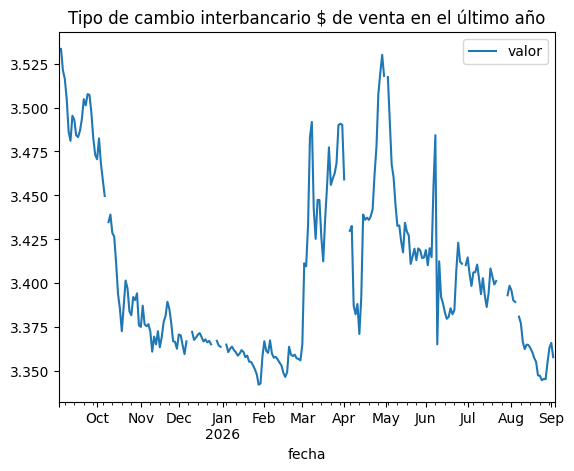

In [ ]:
cod_serie_venta = "PD04638PD"
dias_totales = 365

fin = date.today()
inicio = fin - timedelta(days=dias_totales)
tabla_ejercicio = obtener_serie_bcrp(cod_serie_venta, f"{inicio.year}-{inicio.month}-{inicio.day}",
                                      f"{fin.year}-{fin.month}-{fin.day}")
tabla_ejercicio_limpia = limpiar_tabla_bcrp(tabla_ejercicio)
tabla_ejercicio_limpia.plot(x="fecha", y="valor", title="Tipo de cambio interbancario $ de venta en el último año")

#CLASE 3

>🎯 **Mini actividad (5 min):** cambia el año en la URL y observa cómo cambia la cantidad de películas que trae la respuesta. Prueba con cualquier año entre 2010 y 2015.

**Qué hace:** repite la petición con un parámetro distinto.
**Por qué así:** así confirmamos que `year` es un parámetro real que controla la
respuesta — el primer paso para entender el "patrón" de un endpoint.
**Qué esperamos ver:** un número de películas, probablemente distinto al de 2015.

In [ ]:
# Cambia el año y observa cuántas películas trae (usaremos todos los años)
# Recorremos varios años (el "patrón de paginación" de este endpoint) con pausas
tablas_por_anio = []
for anio in range(2010, 2016):
    url_anio = f"https://www.scrapethissite.com/pages/ajax-javascript/?ajax=true&year={anio}"
    respuesta_anio = requests.get(url_anio, timeout=10)
    datos_anio = respuesta_anio.json()
    time.sleep(1)  # Regla ética #4: no sobrecargar el servidor
    print(f"Año {anio}: {len(datos_anio)} películas")

Año 2010: 13 películas
Año 2011: 15 películas
Año 2012: 15 películas
Año 2013: 12 películas
Año 2014: 16 películas
Año 2015: 16 películas


>🎯 **Mini actividad (8–10 min):** encuentra el endpoint del portal asignado, siguiendo los pasos 2 a 4, y complétalo abajo.

**Qué hace:** aplica todo el flujo de hoy (headers, endpoint, `.json()`) a un
sitio nuevo, sin ayuda.
**Por qué así:** Documenta un endpoint no publicado.
**Qué esperamos ver:** el código de estado y una vista previa del JSON de tu
portal asignado.

In [ ]:
# Reemplaza esta URL por el endpoint que encontraste en tu portal
# COMPLETA AQUÍ (valor de ejemplo funcional mientras no tengas el tuyo):
url_portal_asignado = "https://dataondemand.bvl.com.pe/v1/stock-quote/daily?nemonico=VOLCABC1&today=2026-08-31"
encabezados_portal = {"User-Agent": "TallerWebScrapingPUCP/1.0 (uso educativo para la tarea)"}
respuesta_portal = requests.get(url_portal_asignado, headers=encabezados_portal, timeout=10)
print(respuesta_portal.status_code)
datos_portal = respuesta_portal.json()
print(datos_portal[:2] if isinstance(datos_portal, list) else datos_portal)

200
[{'nemonico': 'VOLCABC1', 'lastDate': '2026-09-03T18:17:16', 'lastValue': 0.87, 'currency': 'S/'}, {'nemonico': 'VOLCABC1', 'lastDate': '2026-09-03T17:48:26', 'lastValue': 0.87, 'currency': 'S/'}]


#RETO DE LA CLASE 3

>🎯 **Reto opcional**

Encuentra un segundo endpoint oculto (en cualquier página que uses seguido) y documenta: URL, parámetros, y qué trae la respuesta.


In [ ]:
!curl --url 'https://urbania.pe/rplis-api/postings' \
  -H 'accept: */*' \
  -H 'accept-language: es-419,es;q=0.8' \
  -H 'content-type: application/json' \
  -b 'cf_clearance=oLGk6hEgYLkwhArTahfY9UoqkFqKb8gVA5p6ktWXzpk-1788216695-1.2.1.1-w2J0Ymdx8LlMo7.itQ7wJWhXhjsJ_adfEY0igBnubaeqp31sVfZiF_hH6XniR3B.fz_RXq36idN.u7z1K7sDgon_LQUnBFq7goSVY13iXxWDIMsOgHcah.EuJj7bB7qpAJJbk2LEl6SBpHKPyqxIS9ubZ0hNFCXGC4EF8k49GFJ3LY29T4rX4J0EOjQmequ80Cs1J.qm5n.18NlWJ_wWURk7pfNldVk7gOIGa3MgttupLPvMwbOSujT_M.g7h3sUiPrVMDQHoBxMTaBnneezPrAYf0HUxqt0t7tMpXM0S8g5usuNpVeHsqI_q9jy5E7n9KE8jyLd3r3kCJrva7MRO9xegNh7IuKJtw5MUPXa2xk; __cf_bm=hH_miR0niccI.Lg.UqVrbYPUWD6Bkryu_f9683OvCKM-1788216695.9347587-1.0.1.1-i2TtiXCN.r2ADsHM1ZEQTPOmsJLiRNO9SyiXZOa4ZZwQNpZQ2QYXxJQjYmNooK6iMr85a69ukX5wn_hidZVqHKYadVLUuxiUvk5KbdsSYGap4SMlsZTd1rL6eqb1dIP9FwRVsRcG9IJAkd9TdQh8uQ; sessionId=3febc704-d17b-4019-853f-73580144e53d; countNotActionSA=1; JSESSIONID=79B91B7BDEE0A3D5BAA4956A7275CEA5; g_state={"i_l":0,"i_ll":1788216722166,"i_b":"63zwseS9nTxB6GK+96MsE7I6JVmWWwhG7SXM54nVrNs","i_e":{"enable_itp_optimization":24},"i_et":1788216722166}' \
  -H 'origin: https://urbania.pe' \
  -H 'priority: u=1, i' \
  -H 'referer: https://urbania.pe/buscar/venta-de-departamentos' \
  -H 'sec-ch-ua: "Not=A?Brand";v="99", "Brave";v="151", "Chromium";v="151"' \
  -H 'sec-ch-ua-mobile: ?0' \
  -H 'sec-ch-ua-platform: "macOS"' \
  -H 'sec-fetch-dest: empty' \
  -H 'sec-fetch-mode: cors' \
  -H 'sec-fetch-site: same-origin' \
  -H 'sec-gpc: 1' \
  -H 'user-agent: Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/151.0.0.0 Safari/537.36' \
  -H 'x-requested-with: XMLHttpRequest' \
  -H 'x-search-id: 7c19df5a-9970-451a-964c-1bdf56556511' \
  --data-raw '{"q":null,"direccion":null,"moneda":"","preciomin":null,"preciomax":null,"services":"","general":"","searchbykeyword":"","amenidades":"","caracteristicasprop":null,"comodidades":"","disposicion":null,"roomType":"","outside":"","areaPrivativa":"","areaComun":"","multipleRets":"","tipoDePropiedad":"2","subtipoDePropiedad":null,"tipoDeOperacion":"1","garages":null,"antiguedad":null,"expensasminimo":null,"expensasmaximo":null,"withoutguarantor":null,"habitacionesminimo":0,"habitacionesmaximo":0,"ambientesminimo":0,"ambientesmaximo":0,"banos":null,"superficieCubierta":1,"idunidaddemedida":1,"metroscuadradomin":null,"metroscuadradomax":null,"tipoAnunciante":"ALL","grupoTipoDeMultimedia":"","publicacion":null,"sort":"relevance","etapaDeDesarrollo":"","auctions":null,"polygonApplied":null,"idInmobiliaria":null,"excludePostingContacted":"","banks":"","places":"","condominio":"","preTipoDeOperacion":"","pagina":2,"city":null,"province":null,"zone":null,"valueZone":null,"subZone":null,"coordenates":null}'

<!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" content="IE=Edge"><meta name="robots" content="noindex,nofollow"><meta name="viewport" content="width=device-width,initial-scale=1"><meta http-equiv="content-security-policy" content="default-src &#39;none&#39;; script-src &#39;nonce-SvRcygBk52Ju3t4zSQ5RR9&#39; &#39;unsafe-eval&#39; https://challenges.cloudflare.com; script-src-attr &#39;none&#39;; style-src &#39;unsafe-inline&#39;; img-src &#39;self&#39; https://challenges.cloudflare.com; connect-src &#39;self&#39; https://challenges.cloudflare.com; frame-src &#39;self&#39; https://challenges.cloudflare.com blob:; child-src &#39;self&#39; https://challenges.cloudflare.com blob:; worker-src blob:; form-action http: https:; base-uri &#39;self&#39;"><style>*{box-sizing:border-box;margin:0;padding:0}html{line-height:1.15;-webkit-text-size-adjust:100%;color:#313131;font

In [ ]:
url_base = "https://urbania.pe" #para chequear url base y robots para ética
respuesta_robots = requests.get(url_base + "/robots.txt", timeout=10)
print(respuesta_robots.status_code)
print(respuesta_robots.text)

200
Sitemap: https://urbania.pe/sitemaps_https.xml
Sitemap: https://urbania.pe/sitemaps_list_emp_https.xml
Sitemap: https://urbania.pe/sitemaps_prop_emp_https.xml
Sitemap: https://urbania.pe/blog/sitemap_index.xml

User-agent: Linguee
Disallow: /

User-agent: UbiCrawler
Disallow: /

User-agent: DOC
Disallow: /

User-agent: Zao
Disallow: /

User-agent: Zealbot
Disallow: /

User-agent: MSIECrawler
Disallow: /

User-agent: SiteSnagger
Disallow: /

User-agent: WebStripper
Disallow: /

User-agent: WebCopier
Disallow: /

User-agent: Fetch
Disallow: /

User-agent: Offline Explorer
Disallow: /

User-agent: Teleport
Disallow: /

User-agent: TeleportPro
Disallow: /

User-agent: WebZIP
Disallow: /

User-agent: linko
Disallow: /

User-agent: HTTrack
Disallow: /

User-agent: larbin
Disallow: /

User-agent: libwww
Disallow: /

User-agent: ZyBORG
Disallow: /

User-agent: Download Ninja
Disallow: /

User-agent: wget
Disallow: /

User-agent: grub-client
Disallow: /

User-agent: k2spider
Disallow: /

Us

In [ ]:
url_endpoint2 = "https://urbania.pe/rplis-api/postings" # Usaremos las paginas permitidas y obviaremos las categorias deshabilitadas
respuesta = requests.get(url_endpoint2, timeout=10)
print(respuesta.status_code)
print(respuesta.headers.get("Content-Type")) #Podemos apreciar que nos rechazaron la conexion vía 403, no nos quieren dar acceso
# Si tuvieramos acceso procederíamos con lo siguiente y documentariamos los parámetros de compras de departamentos:
encabezados = {
    "User-Agent": "Mozilla/5.0 (taller-webscraping-pucp)",
    "Referer": "https://www.scrapethissite.com/pages/ajax-javascript/",
    "X-Requested-With": "XMLHttpRequest",
}
respuesta = requests.get(url_endpoint2, headers=encabezados, timeout=10)
print(respuesta.status_code)


403
text/html; charset=UTF-8
403


#CLASE 4

>🎯 **Mini actividad (5 min)**

Del **tercer libro** de la portada (`articulos[2]`), extrae:

- `titulo_3`: el atributo `title` del enlace dentro de `h3`.
- `precio_3`: el texto de `p.price_color`, limpio con `get_text(strip=True)`.

Puedes usar notación de punto, `find` o `select`. Imprime ambos separados por `|`.

In [ ]:
!pip install -q requests pandas beautifulsoup4 lxml

In [ ]:
import time
import requests
import pandas as pd
from io import StringIO
from bs4 import BeautifulSoup

print("Librerías listas")

Librerías listas


In [ ]:
url_base = "http://books.toscrape.com/"

time.sleep(1)

respuesta = requests.get(url_base, timeout=10)

print(respuesta.status_code)
print(respuesta.headers["content-type"])
print(respuesta.text[:300])

200
text/html
<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html lan


In [ ]:
sopa = BeautifulSoup(respuesta.content, "html.parser")

print(sopa.title.get_text(strip=True))
print(sopa.h1.get_text(strip=True))

All products | Books to Scrape - Sandbox
All products


In [ ]:
articulos = sopa.find_all("article", class_="product_pod")

print(len(articulos), "articulos")

tercer_articulo = articulos[2]

titulo_3 = tercer_articulo.select_one("h3 a")["title"]
precio_3 = tercer_articulo.select_one("p.price_color").get_text(strip=True)

print(titulo_3, "|", precio_3)

20 articulos
Soumission | £50.10


>🎯 **Mini actividad (8–10 minutos)**

Construye `tu_tabla`: un `DataFrame` de las **páginas 1 y 2** (40 libros) con tres columnas:

- `titulo`
- `precio_libras` (sin `£`, tipo float)
- `valoracion` (usa la función `obtener_valoracion`)

La estructura de paginación ya está escrita; tú armas la **fila** donde dice `COMPLETA AQUÍ`. Recuerda `time.sleep(1)` entre páginas.

In [ ]:
def obtener_valoracion(articulo):
    parrafo = articulo.find("p", class_="star-rating")
    if parrafo is None:
        return None
    return parrafo["class"][1]

print(obtener_valoracion(articulos[0]))

articulo_min = BeautifulSoup("<article><h3>sin datos</h3></article>", "html.parser")
print("sin rating devuelve:", obtener_valoracion(articulo_min.article))

Three
sin rating devuelve: None


In [ ]:
filas_turno = []

for numero_pagina in range(1, 3):
    respuesta_n = requests.get(url_base + f"catalogue/page-{numero_pagina}.html", timeout=10)
    sopa_n = BeautifulSoup(respuesta_n.content, "html.parser")

    for articulo in sopa_n.find_all("article", class_="product_pod"):
        precio_texto = articulo.find("p", class_="price_color").get_text(strip=True)
        filas_turno.append([
            articulo.h3.a["title"],
            float(precio_texto.replace("£", "")),
            obtener_valoracion(articulo),
        ])
    time.sleep(1)

tu_tabla = pd.DataFrame(filas_turno, columns=["Título", "Precio_Libras", "Valoración"])
print(tu_tabla.shape)
tu_tabla.head()

(40, 3)


,Título,Precio_Libras,Valoración
0,A Light in the Attic,51.77,Three
1,Tipping the Velvet,53.74,One
2,Soumission,50.10,One
3,Sharp Objects,47.82,Four
4,Sapiens: A Brief History of Humankind,54.23,Five


#CLASE 5

>🎯 **Tu turno**

**8 a 10 minutos.** Elijan otro sitio peruano (puede ser uno con el que
trabajaron en clases anteriores) y:

1. Scrapéenlo con Firecrawl y guarden el resultado en `mi_markdown`
2. Impriman los primeros 300 caracteres
3. Anoten en un comentario si ese sitio tenía una API oficial u oculta
   que hubiera sido más barata que usar IA

# T2 PROYECTO FINAL

Notebook propio que extraiga un dataset de su interés, usando cualquier escalón de la escalera.

Criterio central: no se premia la técnica más compleja. Un proyecto que usa una API oficial bien documentada, y que justifica por qué se paró en ese escalón, vale más que uno que automatiza un navegador sin necesidad. Esa justificación debe estar escrita en una celda markdown al inicio del notebook que entreguen.

# **Extracción de datos de una API de Pronóstico Meteorológico (Open-Meteo)**

> ## Objetivo del Proyecto
El objetivo de este notebook es extraer en tiempo real el pronóstico meteorológico diario (temperaturas máximas, mínimas y precipitaciones) para la ciudad de Lima a través de la API pública de Open-Meteo, con el fin de estructurar un DataFrame en pandas y realizar un análisis exploratorio de datos (EDA).

> ## Escalón utilizado: Escalón 1 - API Oficial Pública
* ### Fuente oficial: Open Meteo Weather API (https://open-meteo.com/)
* ### Endpoint: https://api.open-meteo.com/v1/forecas

> ## Justificación de la elección del escalón
La plataforma Open-Meteo provee una API REST oficial que no requiere llaves de autenticación ni registro, lo cual permite realizar consultas directamente por código de forma totalmente legítima. Asimismo, entrega datos en arreglos numéricos limpios y estandarizados, siendo el escalón de menor costo computacional y el más eficiente para obtener variables climáticas dinámicas en tiempo real.

In [ ]:
# Instalación de librerías
!pip install -q requests pandas matplotlib

Datos extraídos de la API de Open-Meteo de manera exitosa


,Fecha,Temp_Max_C,Temp_Min_C,Lluvia_mm
0,2026-09-03,23.0,19.1,0.0
1,2026-09-04,23.1,17.9,0.0
2,2026-09-05,23.3,18.5,0.0
3,2026-09-06,23.4,19.1,0.0
4,2026-09-07,23.2,19.6,0.0


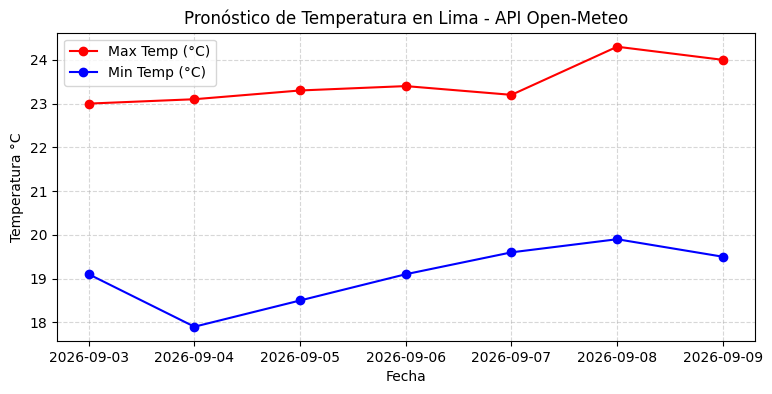

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Endpoint oficial de Open-Meteo para Lima (Latitud: -12.0464, Longitud: -77.0428)
url_clima = "https://api.open-meteo.com/v1/forecast?latitude=-12.0464&longitude=-77.0428&daily=temperature_2m_max,temperature_2m_min,precipitation_sum&timezone=America%2FLima"

respuesta = requests.get(url_clima, timeout=10)

if respuesta.status_code == 200:
    datos = respuesta.json()
    daily = datos['daily']

    # Crear DataFrame (temperaturas en celsius)
    df_clima = pd.DataFrame({
        'Fecha': daily['time'],
        'Temp_Max_C': daily['temperature_2m_max'],
        'Temp_Min_C': daily['temperature_2m_min'],
        'Lluvia_mm': daily['precipitation_sum']
    })

    print("Datos extraídos de la API de Open-Meteo de manera exitosa")
    display(df_clima.head())

    # Gráfico simple
    plt.figure(figsize=(9, 4))
    plt.plot(df_clima['Fecha'], df_clima['Temp_Max_C'], label='Max Temp (°C)', color='red', marker='o')
    plt.plot(df_clima['Fecha'], df_clima['Temp_Min_C'], label='Min Temp (°C)', color='blue', marker='o')
    plt.title('Pronóstico de Temperatura en Lima - API Open-Meteo')
    plt.xlabel('Fecha')
    plt.ylabel('Temperatura °C')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()
else:
    print("Error HTTP:", respuesta.status_code)


In [ ]:
respuesta_robots = requests.get(url_clima + "/robots.txt", timeout=10)
print(respuesta_robots.status_code)
print(respuesta_robots.text)

400
{"reason":"Invalid timezone","error":true}
